# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhamad Nafi Mulyo | 5054251005 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)


PyTorch 2.15.0+cu132 | device: cpu


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("data/fashion-mnist_train.csv")
test_df = pd.read_csv("data/fashion-mnist_test.csv")
print("Train:", train_df.shape)
print("Test :", test_df.shape)
train_df.head()


Train: (60000, 785)
Test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


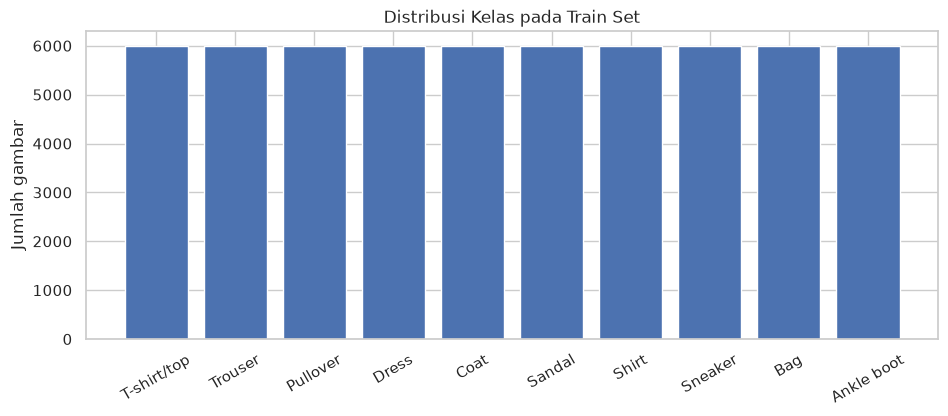

label
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64


In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(11, 4))
plt.bar(CLASS_NAMES, counts.values, color="#4C72B0")
plt.title("Distribusi Kelas pada Train Set")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=30)
plt.show()
print(counts.rename(index=dict(enumerate(CLASS_NAMES))))


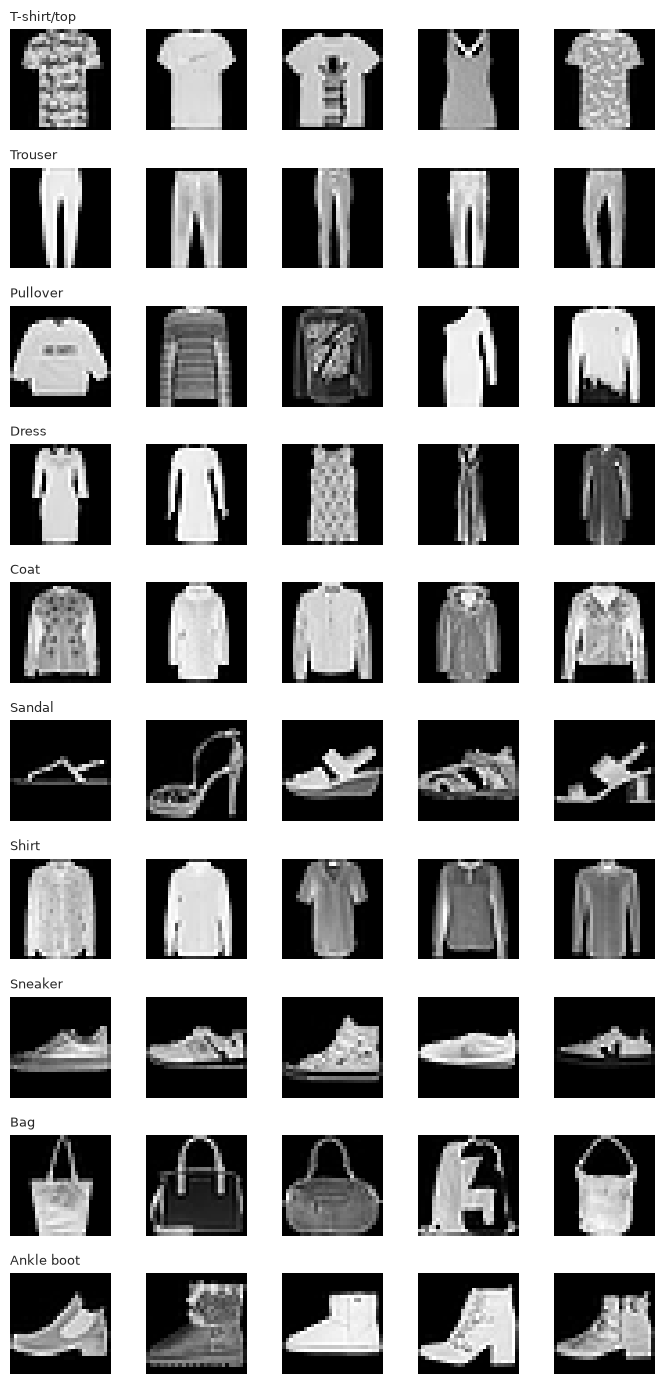

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(7, 14))
for label in range(10):
    samples = train_df[train_df["label"] == label].iloc[:5, 1:].values
    for j in range(5):
        ax = axes[label, j]
        ax.imshow(samples[j].reshape(28, 28), cmap="gray")
        ax.axis("off")
    axes[label, 0].set_title(CLASS_NAMES[label], loc="left", fontsize=9)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

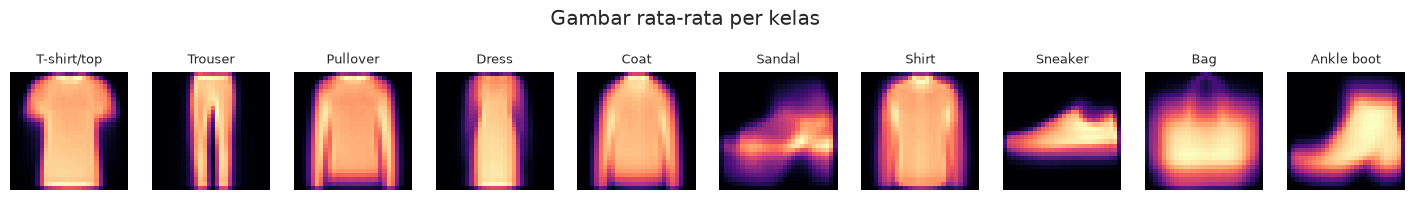

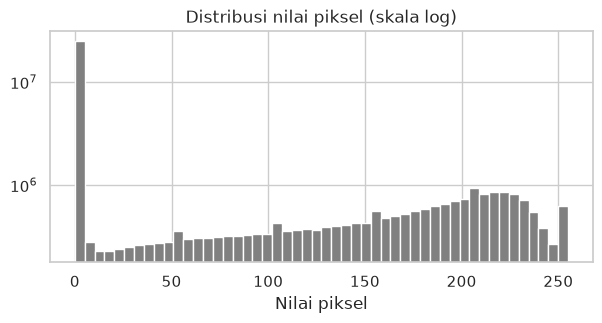

Missing value: 0


In [5]:
# EDA tambahan: gambar rata-rata tiap kelas dan sebaran intensitas piksel
fig, axes = plt.subplots(1, 10, figsize=(18, 2.5))
for label, ax in enumerate(axes):
    mean_img = train_df[train_df["label"] == label].iloc[:, 1:].values.mean(axis=0)
    ax.imshow(mean_img.reshape(28, 28), cmap="magma")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Gambar rata-rata per kelas")
plt.show()

pixels = train_df.iloc[:, 1:].values
plt.figure(figsize=(7, 3))
plt.hist(pixels.ravel(), bins=50, color="gray")
plt.yscale("log")
plt.title("Distribusi nilai piksel (skala log)")
plt.xlabel("Nilai piksel")
plt.show()
print("Missing value:", train_df.isnull().sum().sum() + test_df.isnull().sum().sum())


# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_full = train_df["label"].values
X_full = train_df.drop(columns=["label"]).values
y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values
print(X_full.shape, y_full.shape, X_test.shape, y_test.shape)


(60000, 784) (60000,) (10000, 784) (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_full = X_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print("Rentang piksel:", X_full.min(), "-", X_full.max())


Rentang piksel: 0.0 - 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.10, stratify=y_full, random_state=SEED)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)


Train: (54000, 784) | Val: (6000, 784) | Test: (10000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

def to_tensor(X, y):
    return (torch.tensor(X, dtype=torch.float32).view(-1, 1, 28, 28),
            torch.tensor(y, dtype=torch.long))

Xtr_t, ytr_t = to_tensor(X_train, y_train)
Xva_t, yva_t = to_tensor(X_val, y_val)
Xte_t, yte_t = to_tensor(X_test, y_test)

BATCH_SIZE = 128
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(Xva_t, yva_t), batch_size=512)
test_loader = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=512)
print(Xtr_t.shape, ytr_t.dtype)


torch.Size([54000, 1, 28, 28]) torch.int64


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(SEED)
model_ann = ANN().to(device)
print(model_ann)
print("Jumlah parameter:", count_params(model_ann))


ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

EPOCHS = 15
LR = 1e-3
criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total_loss += criterion(out, yb).item() * len(yb)
        correct += (out.argmax(dim=1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n

def train_model(model, epochs=EPOCHS, lr=LR):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        run_loss, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
        # metrik train diambil dari running average selama epoch (lebih cepat daripada evaluasi ulang)
        tr_loss, tr_acc = run_loss / n, correct / n
        va_loss, va_acc = evaluate(model, val_loader)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc); history["val_acc"].append(va_acc)
        print(f"Epoch {epoch:2d} | loss {tr_loss:.4f} / val {va_loss:.4f} | "
              f"acc {tr_acc:.4f} / val {va_acc:.4f} | {time.time() - start:.0f}s")
    return history

hist_ann = train_model(model_ann)


Epoch  1 | loss 0.5889 / val 0.4651 | acc 0.7931 / val 0.8287 | 7s


Epoch  2 | loss 0.4020 / val 0.3743 | acc 0.8555 / val 0.8650 | 16s


Epoch  3 | loss 0.3521 / val 0.3892 | acc 0.8728 / val 0.8543 | 20s


Epoch  4 | loss 0.3268 / val 0.3391 | acc 0.8799 / val 0.8783 | 22s


Epoch  5 | loss 0.3082 / val 0.3396 | acc 0.8873 / val 0.8790 | 23s


Epoch  6 | loss 0.2893 / val 0.3278 | acc 0.8924 / val 0.8823 | 25s


... (5 outputs left out)

Epoch 12 | loss 0.2250 / val 0.3116 | acc 0.9155 / val 0.8898 | 53s


Epoch 13 | loss 0.2155 / val 0.3175 | acc 0.9193 / val 0.8880 | 58s


Epoch 14 | loss 0.2100 / val 0.3035 | acc 0.9217 / val 0.8905 | 68s


Epoch 15 | loss 0.2019 / val 0.3112 | acc 0.9234 / val 0.8920 | 70s


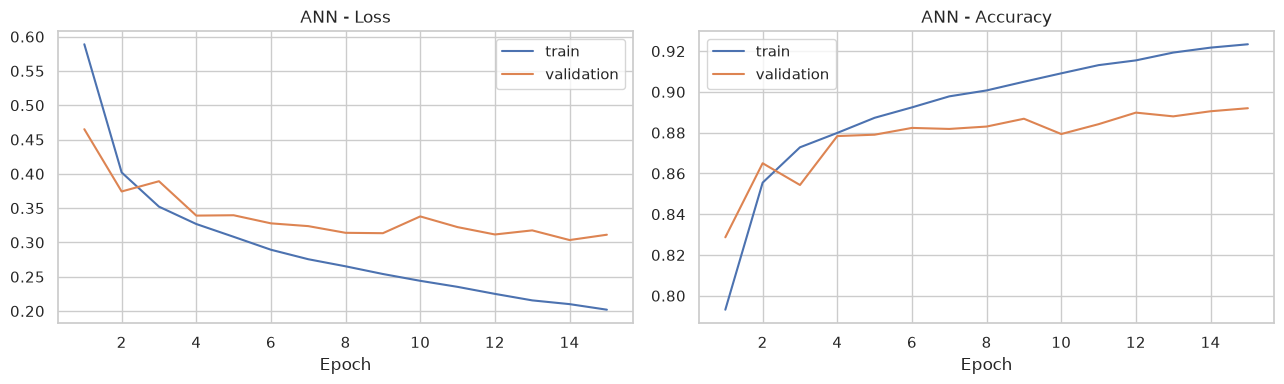

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "acc"]):
        ax.plot(range(1, len(history[f"train_{metric}"]) + 1), history[f"train_{metric}"], label="train")
        ax.plot(range(1, len(history[f"val_{metric}"]) + 1), history[f"val_{metric}"], label="validation")
        ax.set_title(f"{title} - {'Loss' if metric == 'loss' else 'Accuracy'}")
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(hist_ann, "ANN")


In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds = [model(xb.to(device)).argmax(dim=1).cpu() for xb, _ in loader]
    return torch.cat(preds).numpy()

results = {}  # nama model -> (y_pred, model)
results["ANN"] = (predict(model_ann, test_loader), model_ann)
print("Test accuracy ANN:", accuracy_score(y_test, results["ANN"][0]))


Test accuracy ANN: 0.8911


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

# Perhitungan manual dengan rumus (W - K + 2P) / S + 1:
# Input                       : 1 x 28 x 28
# Conv2d(1, 32, k=3, p=1, s=1): (28 - 3 + 2)/1 + 1 = 28  -> 32 x 28 x 28
# MaxPool2d(2)  (k=2, s=2)    : (28 - 2)/2 + 1     = 14  -> 32 x 14 x 14
# Conv2d(32, 64, k=3, p=1)    : (14 - 3 + 2)/1 + 1 = 14  -> 64 x 14 x 14
# MaxPool2d(2)                : (14 - 2)/2 + 1     = 7   -> 64 x 7 x 7
# Flatten                     : 64 * 7 * 7 = 3136 -> input nn.Linear pertama

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
model_cnn = SimpleCNN().to(device)
print(model_cnn)
print("Jumlah parameter:", count_params(model_cnn))

with torch.no_grad():
    out = model_cnn.features(torch.zeros(1, 1, 28, 28, device=device))
print("Bentuk output bagian konvolusi:", tuple(out.shape), "->", out.numel(), "fitur setelah Flatten")


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Bentuk output bagian konvolusi: (1, 64, 7, 7) -> 3136 fitur setelah Flatten


Epoch  1 | loss 0.5451 / val 0.4007 | acc 0.8046 / val 0.8527 | 27s


Epoch  2 | loss 0.3366 / val 0.3265 | acc 0.8789 / val 0.8825 | 56s


Epoch  3 | loss 0.2886 / val 0.2998 | acc 0.8956 / val 0.8843 | 82s


Epoch  4 | loss 0.2593 / val 0.2629 | acc 0.9060 / val 0.9018 | 107s


Epoch  5 | loss 0.2391 / val 0.2462 | acc 0.9132 / val 0.9092 | 132s


Epoch  6 | loss 0.2171 / val 0.2652 | acc 0.9214 / val 0.9005 | 161s


... (5 outputs left out)

Epoch 12 | loss 0.1326 / val 0.2546 | acc 0.9511 / val 0.9115 | 346s


Epoch 13 | loss 0.1203 / val 0.2291 | acc 0.9560 / val 0.9202 | 373s


Epoch 14 | loss 0.1080 / val 0.2489 | acc 0.9604 / val 0.9192 | 410s


Epoch 15 | loss 0.0941 / val 0.2527 | acc 0.9664 / val 0.9163 | 454s


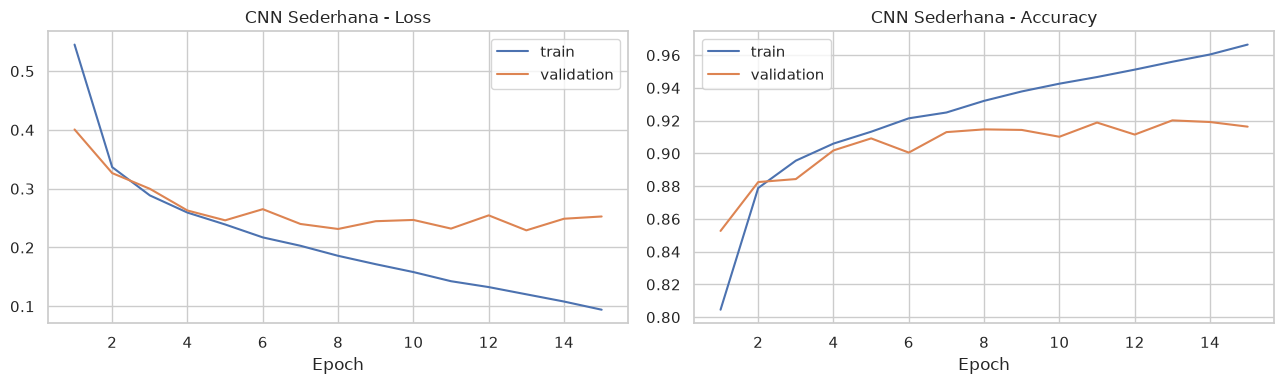

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

hist_cnn = train_model(model_cnn)
plot_history(hist_cnn, "CNN Sederhana")


In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

results["CNN Sederhana"] = (predict(model_cnn, test_loader), model_cnn)
print("Test accuracy CNN Sederhana:", accuracy_score(y_test, results["CNN Sederhana"][0]))


Test accuracy CNN Sederhana: 0.9227


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNNBNDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(SEED)
model_cnn_bn = CNNBNDropout().to(device)
print(model_cnn_bn)
print("Jumlah parameter:", count_params(model_cnn_bn))


CNNBNDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch  1 | loss 0.5288 / val 0.3257 | acc 0.8128 / val 0.8808 | 40s


Epoch  2 | loss 0.3602 / val 0.2806 | acc 0.8708 / val 0.8997 | 94s


Epoch  3 | loss 0.3248 / val 0.2703 | acc 0.8843 / val 0.9028 | 128s


Epoch  4 | loss 0.2845 / val 0.2490 | acc 0.8956 / val 0.9082 | 170s


Epoch  5 | loss 0.2661 / val 0.2471 | acc 0.9048 / val 0.9107 | 219s


Epoch  6 | loss 0.2488 / val 0.2476 | acc 0.9098 / val 0.9097 | 271s


... (5 outputs left out)

Epoch 12 | loss 0.1795 / val 0.2212 | acc 0.9334 / val 0.9213 | 483s


Epoch 13 | loss 0.1690 / val 0.2271 | acc 0.9369 / val 0.9230 | 518s


Epoch 14 | loss 0.1590 / val 0.2252 | acc 0.9401 / val 0.9247 | 556s


Epoch 15 | loss 0.1516 / val 0.2262 | acc 0.9425 / val 0.9247 | 588s


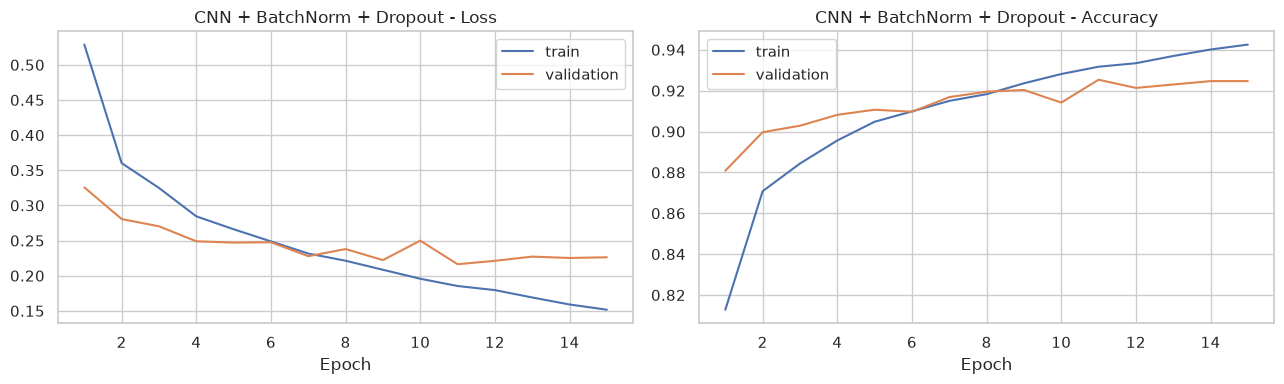

ANN                  gap acc train-val di epoch terakhir: +0.0314
CNN Sederhana        gap acc train-val di epoch terakhir: +0.0501
CNN + BN + Dropout   gap acc train-val di epoch terakhir: +0.0179


In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

hist_cnn_bn = train_model(model_cnn_bn)
plot_history(hist_cnn_bn, "CNN + BatchNorm + Dropout")

for name, h in [("ANN", hist_ann), ("CNN Sederhana", hist_cnn), ("CNN + BN + Dropout", hist_cnn_bn)]:
    print(f"{name:20s} gap acc train-val di epoch terakhir: {h['train_acc'][-1] - h['val_acc'][-1]:+.4f}")


In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

results["CNN + BN + Dropout"] = (predict(model_cnn_bn, test_loader), model_cnn_bn)
print("Test accuracy CNN + BN + Dropout:", accuracy_score(y_test, results["CNN + BN + Dropout"][0]))


Test accuracy CNN + BN + Dropout: 0.928


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

rows = []
for name, (pred, model) in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1-Score (macro)": f1_score(y_test, pred, average="macro"),
        "Jumlah Parameter": count_params(model),
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
best_name = metrics_df["F1-Score (macro)"].idxmax()
best_pred, best_model = results[best_name]
print("Model terbaik:", best_name)
metrics_df


Model terbaik: CNN + BN + Dropout


,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.8911,0.8912,0.8911,0.8910,235146
CNN Sederhana,0.9227,0.9244,0.9227,0.9228,421642
CNN + BN + Dropout,0.9280,0.9278,0.9280,0.9278,421834


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(f"Classification report - {best_name}")
print(classification_report(y_test, best_pred, target_names=CLASS_NAMES, digits=4))


Classification report - CNN + BN + Dropout
              precision    recall  f1-score   support

 T-shirt/top     0.8849    0.8690    0.8769      1000
     Trouser     0.9960    0.9920    0.9940      1000
    Pullover     0.8878    0.8940    0.8909      1000
       Dress     0.9200    0.9430    0.9314      1000
        Coat     0.8986    0.9040    0.9013      1000
      Sandal     0.9811    0.9870    0.9840      1000
       Shirt     0.8008    0.7840    0.7923      1000
     Sneaker     0.9703    0.9470    0.9585      1000
         Bag     0.9830    0.9840    0.9835      1000
  Ankle boot     0.9550    0.9760    0.9654      1000

    accuracy                         0.9280     10000
   macro avg     0.9278    0.9280    0.9278     10000
weighted avg     0.9278    0.9280    0.9278     10000



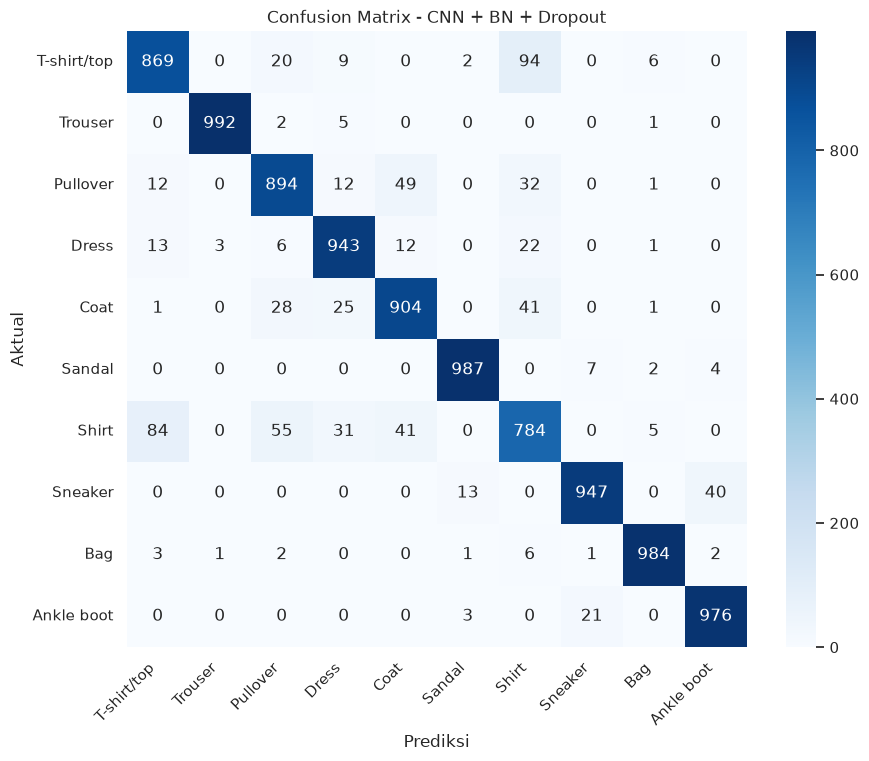

Pasangan kelas yang paling sering tertukar (dua arah):
  T-shirt/top  <-> Shirt       : 178
  Pullover     <-> Shirt       : 87
  Coat         <-> Shirt       : 82
  Pullover     <-> Coat        : 77
  Sneaker      <-> Ankle boot  : 61


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=45, ha="right")
plt.show()

cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = sorted(((cm_off[i, j] + cm_off[j, i], CLASS_NAMES[i], CLASS_NAMES[j])
                for i in range(10) for j in range(i + 1, 10)), reverse=True)[:5]
print("Pasangan kelas yang paling sering tertukar (dua arah):")
for n, a, b in pairs:
    print(f"  {a:12s} <-> {b:12s}: {n}")


Jumlah salah klasifikasi: 720 dari 10000


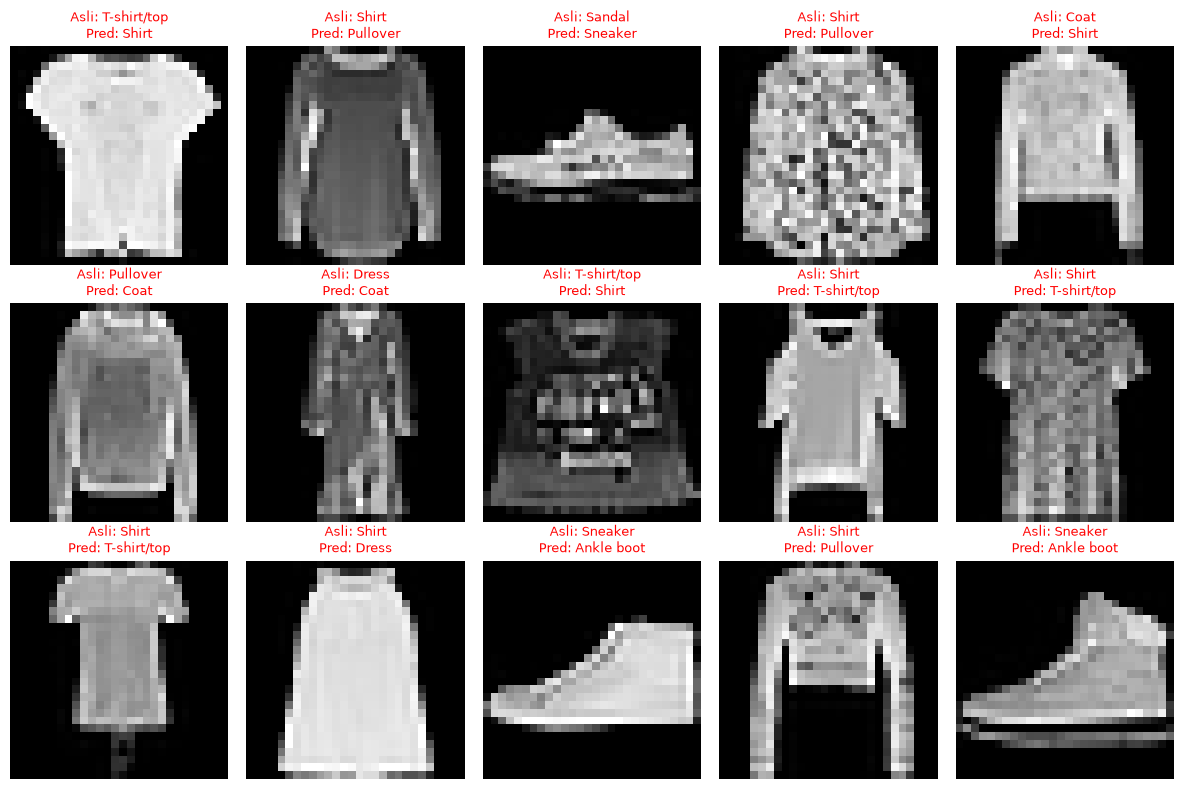

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong = np.where(best_pred != y_test)[0]
print(f"Jumlah salah klasifikasi: {len(wrong)} dari {len(y_test)}")
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(wrong, size=15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[best_pred[idx]]}", fontsize=9, color="red")
    ax.axis("off")
plt.tight_layout()
plt.show()


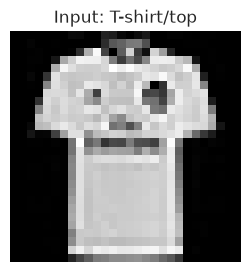

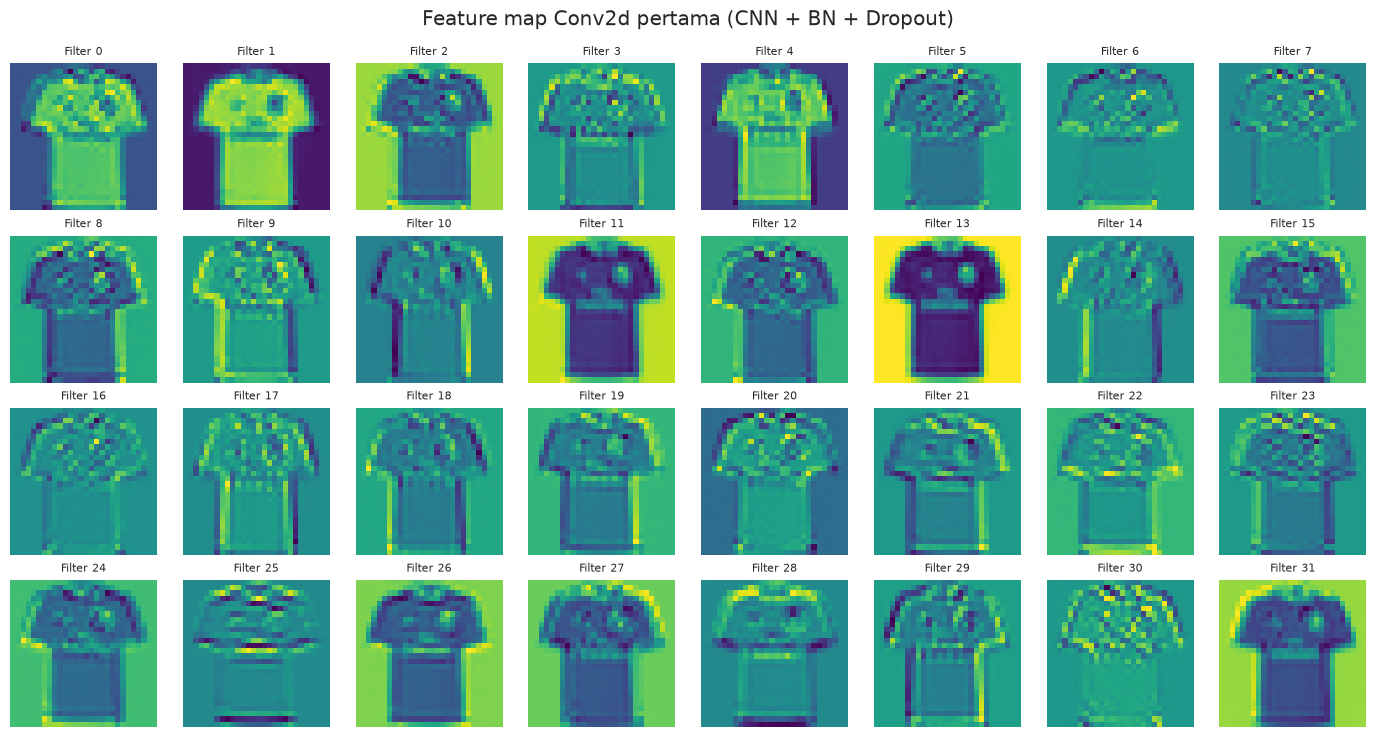

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

sample = Xte_t[0:1].to(device)  # bentuk (1, 1, 28, 28)
best_model.eval()
with torch.no_grad():
    fmap = best_model.features[0](sample).detach().cpu().numpy()[0]  # (32, 28, 28)

plt.figure(figsize=(3, 3))
plt.imshow(sample.cpu().numpy()[0, 0], cmap="gray")
plt.title(f"Input: {CLASS_NAMES[y_test[0]]}")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(14, 7.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(fmap[i], cmap="viridis")
    ax.set_title(f"Filter {i}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Feature map Conv2d pertama ({best_name})")
plt.tight_layout()
plt.show()


In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print(f"Bobot {best_name} disimpan ke model.pth")

# Definisi class model juga disimpan ke model_def.py agar bisa di-import pada tugas Deployment.
# Ambil source class dari riwayat cell (In) karena inspect.getsource tidak bisa membaca class di notebook.
best_cls = type(best_model)
cell_src = next(s for s in reversed(In) if f"class {best_cls.__name__}(" in s)
lines = cell_src.splitlines()
start = next(k for k, l in enumerate(lines) if l.startswith(f"class {best_cls.__name__}("))
end = next((k for k in range(start + 1, len(lines)) if lines[k] and not lines[k][0].isspace()), len(lines))
with open("model_def.py", "w") as f:
    f.write("import torch\nimport torch.nn as nn\n\n\n")
    f.write("\n".join(lines[start:end]).rstrip() + "\n")
    f.write(f"\n\nCLASS_NAMES = {CLASS_NAMES!r}\n")
print(f"Definisi class {best_cls.__name__} disimpan ke model_def.py")

# Cek: muat ulang dan pastikan prediksinya identik
reloaded = best_cls().to(device)
reloaded.load_state_dict(torch.load("model.pth", map_location=device))
print("Prediksi model yang dimuat ulang identik:", np.array_equal(predict(reloaded, test_loader), best_pred))


Bobot CNN + BN + Dropout disimpan ke model.pth
Definisi class CNNBNDropout disimpan ke model_def.py


Prediksi model yang dimuat ulang identik: True


# 5. Analisis

### Analisis

**1. Perbandingan performa ketiga model.**

| Model | Accuracy | F1 (macro) | Parameter | Gap acc train−val (epoch 15) |
|---|---|---|---|---|
| ANN | 0,891 | 0,891 | 235.146 | +3,1% |
| CNN Sederhana | 0,923 | 0,923 | 421.642 | +5,0% |
| CNN + BN + Dropout | **0,928** | **0,928** | 421.834 | **+1,8%** |

Kedua CNN mengungguli ANN sekitar 3–4% accuracy, dan CNN + BatchNorm + Dropout menjadi model terbaik.

**2. Kaitan dengan jumlah parameter dan cara memproses gambar.**
ANN menerima gambar yang sudah di-flatten menjadi 784 angka, sehingga informasi posisi (piksel mana yang bertetangga) hilang dan model harus mempelajari pola untuk setiap posisi piksel secara terpisah. CNN mempertahankan struktur 2D gambar: filter konvolusi 3×3 bergeser ke seluruh gambar dan memakai bobot yang sama di setiap posisi (*weight sharing*), sehingga pola lokal seperti tepi, kerah, atau lengan baju bisa dikenali di mana pun letaknya.

Walaupun total parameter CNN lebih besar, sebagian besar parameternya bukan berada di layer konvolusi. Dua layer konvolusi hanya memiliki sekitar 18,8 ribu parameter (320 + 18.496), sedangkan sekitar 401 ribu parameter berada di `Linear(3136, 128)` setelah Flatten. Jadi keunggulan CNN berasal dari cara memproses gambar, bukan sekadar dari jumlah parameter yang lebih banyak.

**3. Pengaruh Batch Normalization dan Dropout terhadap learning curve.**
- *CNN Sederhana* paling overfit: train loss terus turun hingga 0,094, sedangkan validation loss mencapai titik terendah sekitar epoch 8 lalu naik-turun ke sekitar 0,25. Gap accuracy mencapai 5,0%.
- *CNN + BN + Dropout* jauh lebih stabil: gap accuracy hanya 1,8% dan validation loss tetap di sekitar 0,22–0,23 sampai akhir. Pada beberapa epoch awal, validation accuracy bahkan lebih tinggi daripada train accuracy, karena Dropout hanya aktif saat training dan dimatikan saat evaluasi.
- Dropout membuat neuron tidak terlalu bergantung pada neuron di sekitarnya (mengurangi *co-adaptation*), sedangkan BatchNorm menormalkan output setiap layer konvolusi sehingga training lebih stabil.
- Penambahan ini hanya menambah 192 parameter, tetapi manfaat utamanya adalah **generalisasi yang lebih baik**, bukan kenaikan accuracy (+0,5%) itu sendiri.

**4. Kelas yang sulit dibedakan.**
Berdasarkan classification report, kelas tersulit adalah **Shirt** (F1 0,79), sedangkan yang termudah adalah Trouser (0,99), Sandal (0,98), dan Bag (0,98). Pasangan yang paling sering tertukar adalah T-shirt/top ↔ Shirt (178), Pullover ↔ Shirt (87), Coat ↔ Shirt (82), dan Pullover ↔ Coat (77). Semuanya adalah pakaian atasan dengan siluet yang hampir sama; perbedaannya ada pada detail seperti kerah, kancing, atau tekstur kain, yang banyak hilang pada gambar grayscale 28×28. Trouser, Bag, dan alas kaki memiliki bentuk yang sangat khas sehingga mudah dikenali.


# 6. Kesimpulan dan Saran

### Kesimpulan

- CNN lebih cocok untuk klasifikasi gambar daripada ANN karena mempertahankan struktur spasial gambar dan mengenali pola lokal dengan weight sharing. Peningkatannya sekitar 3–4% accuracy.
- Batch Normalization dan Dropout hanya menaikkan accuracy sedikit (0,923 → 0,928), tetapi mengurangi overfitting secara signifikan (gap train−val dari 5,0% menjadi 1,8%), sehingga model lebih andal pada data baru.
- **Model terbaik adalah CNN + BN + Dropout** dengan accuracy dan F1 macro 0,928. Model ini disimpan ke `model.pth` dan definisi class-nya ke `model_def.py` untuk tugas Deployment.
- Kesalahan terbanyak terjadi pada kelas atasan yang mirip (terutama Shirt), karena detail pembedanya sulit terlihat pada resolusi 28×28.

### Saran
- Menggunakan **data augmentation** (misalnya flip horizontal dan sedikit pergeseran) agar model lebih tahan terhadap variasi gambar.
- Menambah blok konvolusi atau jumlah filter agar detail kecil seperti kerah dan kancing lebih tertangkap.
- Menggunakan **early stopping** dan learning rate scheduler, karena validation loss CNN Sederhana sudah tidak membaik setelah sekitar epoch 8.
- Training dengan GPU agar eksperimen dengan epoch lebih banyak dapat dilakukan lebih cepat.
